# Adaptive Gaussian Voltage Squzze sampling and Julia AC-OPF verification

## 1. Imports, paths, grid, and Julia verifier

In [33]:
import copy
import csv
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

In [34]:
DATASET_NAME = "alabama"
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_voltage_squeeze") / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"

DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))

Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_voltage_squeeze/alabama
Buses: 494 | baseMVA: 100.0


## 2. Voltage-squeeze configuration and original bus IDs

In [35]:
SEED = 42
iterations = 10
samples_per_iteration = 2
alpha = 0.30

min_squeeze = 0.0
max_squeeze = 0.01
INITIAL_SCALE_MIN = 1.0  
INITIAL_SCALE_MAX = 1.8 
COV_REG = 1e-10
assert 0 <= min_squeeze <= max_squeeze
assert 0 < INITIAL_SCALE_MIN <= INITIAL_SCALE_MAX
assert iterations >= 1 and samples_per_iteration >= 1 and 0 < alpha <= 1

# Keep every raw bus, in its actual JSON order; SHAP needs this stable mapping.
bus_ids = [str(x) for x in data["bus"].keys()]
voltage_limits = np.asarray([
    [float(data["bus"][bid]["vmin"]), float(data["bus"][bid]["vmax"])]
    for bid in bus_ids
], dtype=np.float64)
n_buses = len(bus_ids)
assert n_buses >= 2 and np.isfinite(voltage_limits).all()
assert np.all(voltage_limits[:, 0] > 0) and np.all(voltage_limits[:, 0] < voltage_limits[:, 1])

# Assumes each squeezed bus retains 1.0 p.u. inside the
# band even at maximum tightening. Exclude buses that cannot meet that rule,
# and ignore Julia-inactive bus_type==4 buses.
eligible_indices = np.asarray([
    i for i, bid in enumerate(bus_ids)
    if int(data["bus"][bid].get("bus_type", 1)) != 4
    and (voltage_limits[i, 0] + max_squeeze < 1.0)
    and (voltage_limits[i, 1] - max_squeeze > 1.0)
], dtype=np.int64)
n_eligible = len(eligible_indices)
if n_eligible == 0:
    raise ValueError("No buses can be squeezed while retaining 1.0 p.u. inside their bounds")
n_squeezed = min(n_eligible, max(1, round(0.10 * n_eligible)))

# Signed nominal changes. A separate ZERO-CENTERED Gaussian adds noise to them.
# If min=0.0, max=0.01: nominal [+0.00505,-0.00505] p.u.
mid_squeeze = (min_squeeze + max_squeeze) / 2.0
nominal_shift = np.asarray([mid_squeeze, -mid_squeeze], dtype=np.float64)
base_std = (max_squeeze - min_squeeze) / np.sqrt(12.0)
base_cov = np.diag([base_std**2, base_std**2])
scale_rng = np.random.default_rng(SEED + 1)
INITIAL_SCALE = float(scale_rng.uniform(INITIAL_SCALE_MIN, INITIAL_SCALE_MAX))
rng = np.random.default_rng(SEED)
noise_mu = np.zeros(2, dtype=np.float64)
noise_cov = INITIAL_SCALE**2 * base_cov + np.eye(2) * COV_REG
initial_noise_mu = noise_mu.copy()
initial_noise_cov = noise_cov.copy()

history, verification_log = [], []
explain_candidates, explain_labels, explain_metadata = [], [], []
selected_bus_ids_log, squeeze_deltas_log = [], []
last_proposed, last_applied, last_original = None, None, None

print("Original buses:", n_buses, "| eligible:", n_eligible,
      "| selected per scenario:", n_squeezed)
print("Squeezing each boundary by:", (min_squeeze, max_squeeze), "p.u.")
print("Nominal shift [ΔVmin, ΔVmax]:", nominal_shift)
print("Initial scale:", INITIAL_SCALE)
print("Initial extra-noise mean:", noise_mu)
print("Initial extra-noise std:", np.sqrt(np.diag(noise_cov)))
print("Planned Julia solves:", iterations * samples_per_iteration + 1, "(including baseline)")

Original buses: 494 | eligible: 494 | selected per scenario: 49
Squeezing each boundary by: (0.0, 0.01) p.u.
Nominal shift [ΔVmin, ΔVmax]: [ 0.005 -0.005]
Initial scale: 1.5218394101607287
Initial extra-noise mean: [0. 0.]
Initial extra-noise std: [0.00439318 0.00439318]
Planned Julia solves: 21 (including baseline)


## 3. Initialize the existing PowerModels AC-OPF verifier for this case

In [36]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.ACOPFVerifier.initialize_case(str(DATA_PATH.resolve()))
print("Julia case initialized:\n", json.loads(str(summary_text)))


Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864, 'per_unit': True}


## 4. Python wrapper and baseline AC-OPF check

In [39]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = jl.ACOPFVerifier.verify_scenario_json(
            json.dumps(patch, allow_nan=False)
        )
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "reason": str(exc)[:1000], "termination_status": "ERROR",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }


def build_voltage_patch(candidate_limits, selected_ids):
    values = np.asarray(candidate_limits, dtype=np.float64)
    if values.shape != voltage_limits.shape or not np.isfinite(values).all():
        raise ValueError(f"Expected finite voltage matrix {voltage_limits.shape}, got {values.shape}")
    selected_ids = [str(b) for b in selected_ids]
    if not selected_ids or len(set(selected_ids)) != len(selected_ids):
        raise ValueError("selected_ids must be nonempty and unique")
    index = {bid: i for i, bid in enumerate(bus_ids)}
    if any(bid not in index for bid in selected_ids):
        raise ValueError("Patch references unknown bus ID")
    return {"bus": {bid: {"vmin": float(values[index[bid], 0]),
                          "vmax": float(values[index[bid], 1])}
                    for bid in selected_ids}}


def verify_acopf(candidate_limits, selected_ids):
    return verify_scenario(build_voltage_patch(candidate_limits, selected_ids))

In [40]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_bus_id = bus_ids[int(eligible_indices[0])]
baseline_result = verify_acopf(voltage_limits, [baseline_bus_id])
print("Baseline:", baseline_result)
if not baseline_result.get("accepted", False):
    raise RuntimeError("Original case was not confirmed by Julia AC-OPF: " + str(baseline_result))

Verifying the original Alabama case
Baseline: {'stage': 'opf', 'modes': ['bus'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': [], 'applied_components': {'bus': 1}, 'solve_time': 0.6539909839630127, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 0.9533122089924291}


## 5. Voltage perturbation: original bounds + nominal tightening + noise

In [29]:
def sample_voltage_squeeze(rng, original_limits, eligible_indices,
                           noise_mu, noise_cov, n_scenarios):
    n = len(original_limits)
    chosen = np.empty((n_scenarios, n_squeezed), dtype=np.int64)
    applied = np.repeat(original_limits[None, :, :], n_scenarios, axis=0)
    raw_selected = np.empty((n_scenarios, n_squeezed, 2), dtype=np.float64)
    applied_selected = np.empty_like(raw_selected)
    selected_original = np.empty_like(raw_selected)
    realized_noise = np.empty_like(raw_selected)
    clipped_min = clipped_max = reverted = 0
    for k in range(n_scenarios):
        idx = rng.choice(eligible_indices, size=n_squeezed, replace=False)
        chosen[k] = idx
        orig = original_limits[idx]
        extra_noise = rng.multivariate_normal(noise_mu, noise_cov, size=n_squeezed,
                                              check_valid="raise")
        proposed = orig + nominal_shift + extra_noise
        # clip absolute proposed limits to narrow ranges.
        vmin = np.clip(proposed[:, 0], orig[:, 0] + min_squeeze, orig[:, 0] + max_squeeze)
        vmax = np.clip(proposed[:, 1], orig[:, 1] - max_squeeze, orig[:, 1] - min_squeeze)
        clipped_min += int(np.count_nonzero(proposed[:, 0] != vmin))
        clipped_max += int(np.count_nonzero(proposed[:, 1] != vmax))
        bad = (vmin >= vmax)
        reverted += int(bad.sum())
        vmin[bad], vmax[bad] = orig[bad, 0], orig[bad, 1]
        final = np.column_stack((vmin, vmax))
        applied[k, idx] = final
        raw_selected[k] = proposed
        applied_selected[k] = final
        selected_original[k] = orig
        realized_noise[k] = final - orig - nominal_shift
    assert np.isfinite(applied).all() and np.all(applied[..., 0] < applied[..., 1])
    assert np.all(applied_selected[..., 0] < 1.0)
    assert np.all(applied_selected[..., 1] > 1.0)
    diagnostics = dict(total_selected_pairs=n_scenarios*n_squeezed,
                       vmin_clipped_count=clipped_min, vmax_clipped_count=clipped_max,
                       reverted_bus_count=reverted,
                       vmin_clipped_fraction=clipped_min/(n_scenarios*n_squeezed),
                       vmax_clipped_fraction=clipped_max/(n_scenarios*n_squeezed))
    return applied, chosen, realized_noise, raw_selected, applied_selected, selected_original, diagnostics

## 6. Adaptive loop — sampling, verifier, accepted-noise update

In [30]:
for iteration in range(iterations):
    sampled, chosen, applied_noise, raw_selected, applied_selected, selected_original, diag = (
        sample_voltage_squeeze(rng, voltage_limits, eligible_indices, noise_mu, noise_cov,
                               samples_per_iteration))
    good_noise_list = []
    accepted_selected_list = []
    print(f"\nIteration {iteration+1}/{iterations}: "
          f"Vmin clipped {diag['vmin_clipped_fraction']:.1%}, "
          f"Vmax clipped {diag['vmax_clipped_fraction']:.1%}", flush=True)

    for j in range(samples_per_iteration):
        selected_ids = [bus_ids[int(i)] for i in chosen[j]]
        candidate = sampled[j]
        verification = verify_acopf(candidate, selected_ids)
        delta_min = candidate[chosen[j], 0] - voltage_limits[chosen[j], 0]
        delta_max = voltage_limits[chosen[j], 1] - candidate[chosen[j], 1]
        row = dict(iteration=iteration+1, scenario=j+1,
                   n_buses_vsqueezed=n_squeezed,
                   mean_vmin_tightening=float(delta_min.mean()),
                   mean_vmax_tightening=float(delta_max.mean()),
                   max_vmin_tightening=float(delta_min.max()),
                   max_vmax_tightening=float(delta_max.max()),
                   **verification)
        verification_log.append(row)
        explain_candidates.append(candidate.astype(np.float32).copy())
        explain_labels.append(int(verification.get("accepted", False)))
        explain_metadata.append((iteration+1, j+1,
                                 verification.get("status", "UNKNOWN"),
                                 verification.get("termination_status", "UNKNOWN")))
        selected_bus_ids_log.append(selected_ids)
        squeeze_deltas_log.append(np.column_stack((delta_min, delta_max)))
        print(f"{iteration+1}/{iterations}, scenario {j+1}/{samples_per_iteration}: "
              f"{verification.get('status')} ({verification.get('termination_status')}, "
              f"{verification['elapsed_s']:.1f}s) "
              f"mean tightened [Vmin,Vmax]={np.round([delta_min.mean(), delta_max.mean()], 6)}",
              flush=True)
        if verification.get("reason"):
            print("    Reason:", str(verification["reason"])[:300], flush=True)
        if verification.get("accepted", False):
            good_noise_list.append(applied_noise[j].copy())
            accepted_selected_list.append(applied_selected[j].copy())

    accepted_count = len(good_noise_list)
    if accepted_count:
        accepted_noise = np.stack(good_noise_list).reshape(-1, 2)
        new_mu = accepted_noise.mean(axis=0)
        new_cov = (np.cov(accepted_noise, rowvar=False, bias=True)
                   if len(accepted_noise) >= 2 else noise_cov.copy())
        noise_mu = (1.0-alpha)*noise_mu + alpha*new_mu
        noise_cov = (1.0-alpha)*noise_cov + alpha*new_cov
        noise_cov = 0.5*(noise_cov + noise_cov.T) + np.eye(2)*COV_REG

    history.append(dict(iteration=iteration+1, noise_mu=noise_mu.copy(),
                        noise_std=np.sqrt(np.diag(noise_cov)).copy(),
                        noise_cov=noise_cov.copy(), accepted_count=accepted_count,
                        rejected_count=samples_per_iteration-accepted_count,
                        acceptance_rate=accepted_count/samples_per_iteration,
                        updated=bool(accepted_count), **diag))
    last_proposed = raw_selected.copy()
    last_original = selected_original.copy()
    last_applied = (np.concatenate(accepted_selected_list, axis=0)
                    if accepted_count else np.empty((0, 2), dtype=float))

    # checkpoint every iteration for interruption recovery.
    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        bus_ids=np.asarray(bus_ids, dtype=str),
        eligible_bus_ids=np.asarray([bus_ids[int(i)] for i in eligible_indices], dtype=str),
        selected_bus_ids=np.asarray(selected_bus_ids_log, dtype=str),
        squeeze_deltas=np.stack(squeeze_deltas_log),
        iteration=np.asarray([m[0] for m in explain_metadata], dtype=np.int64),
        scenario=np.asarray([m[1] for m in explain_metadata], dtype=np.int64),
        status=np.asarray([m[2] for m in explain_metadata], dtype=str),
        termination_status=np.asarray([m[3] for m in explain_metadata], dtype=str),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        initial_scale=np.asarray(INITIAL_SCALE),
        min_squeeze=np.asarray(min_squeeze),
        max_squeeze=np.asarray(max_squeeze),
        nominal_shift=np.asarray(nominal_shift),
    )
    print(f"Iteration {iteration+1}: Julia accepted {accepted_count}/{samples_per_iteration} | "
          f"noise mu={np.round(noise_mu,6)} | std={np.round(np.sqrt(np.diag(noise_cov)),6)}",
          flush=True)
print("Overall Julia accepted:", sum(h['accepted_count'] for h in history),
      '/', iterations*samples_per_iteration)
print("Scenario archive:", SCENARIO_PATH)


Iteration 1/10: Vmin clipped 19.4%, Vmax clipped 25.5%
1/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 1.0s) mean tightened [Vmin,Vmax]=[0.004649 0.005615]
1/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s) mean tightened [Vmin,Vmax]=[0.004634 0.005378]
Iteration 1: Julia accepted 2/2 | noise mu=[-0.000108 -0.000149] | std=[0.004063 0.004095]

Iteration 2/10: Vmin clipped 19.4%, Vmax clipped 22.4%
2/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s) mean tightened [Vmin,Vmax]=[0.00494  0.004781]
2/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s) mean tightened [Vmin,Vmax]=[0.004592 0.004737]
Iteration 2: Julia accepted 2/2 | noise mu=[-1.46e-04 -3.20e-05] | std=[0.003796 0.003888]

Iteration 3/10: Vmin clipped 14.3%, Vmax clipped 23.5%
3/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s) mean tightened [Vmin,Vmax]=[0.004198 0.005503]
3/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 1.0s) mean tightened [Vmin,Vmax]=[0.004751 0.005343]
Iteration 3: Julia accepted 2/2 | noise mu=[

## 7. Virtualize Julia acceptance, Gaussian noise evolution, and applied voltage limits

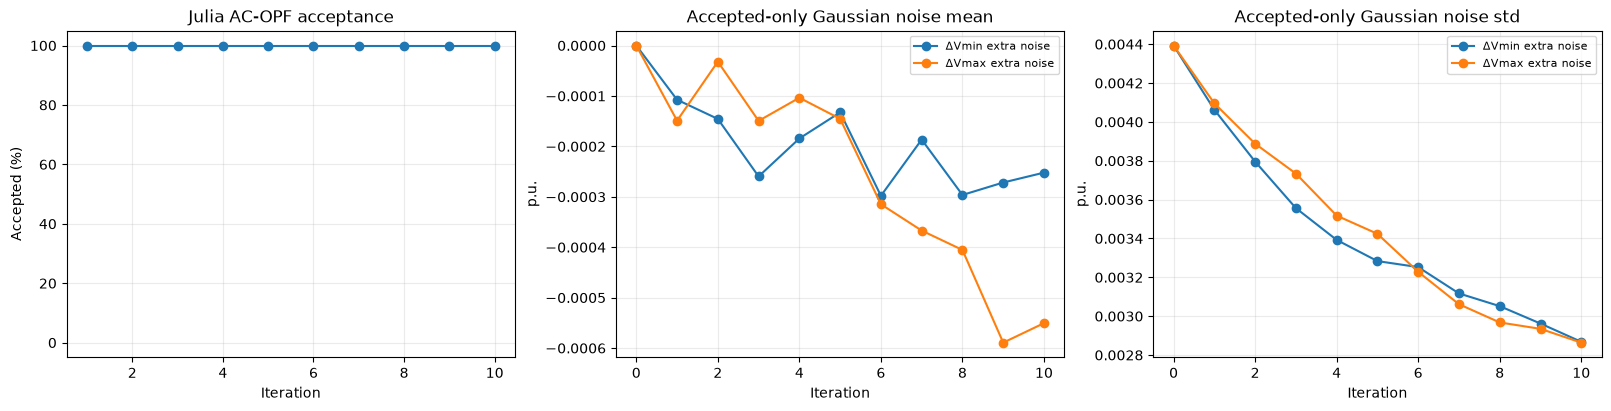

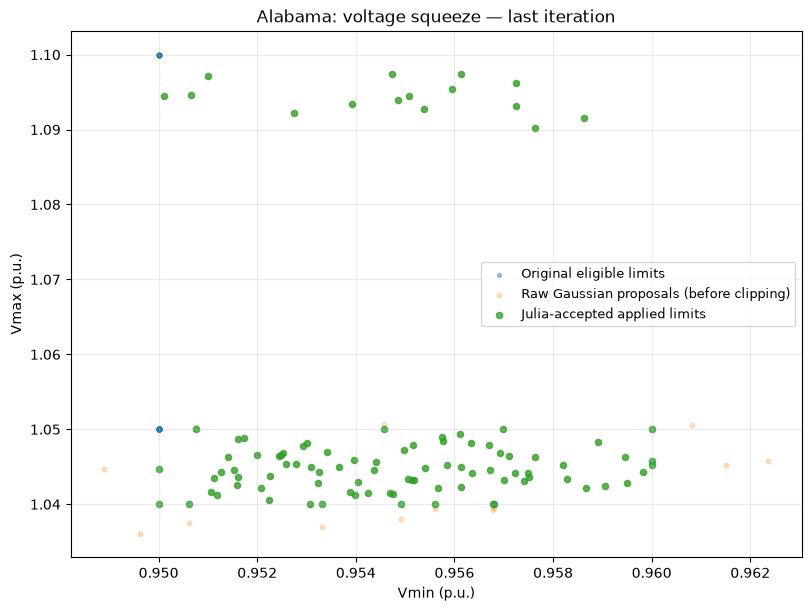

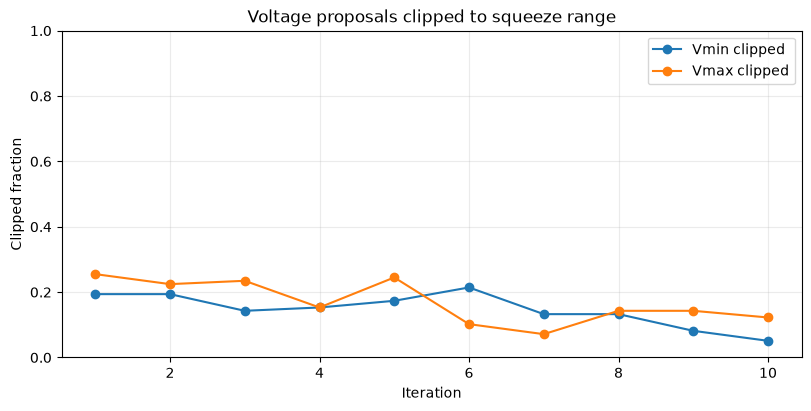

In [31]:
xs = [h["iteration"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5,105))
for j, name in enumerate(("Vmin", "Vmax")):
    axes[1].plot([0]+xs, [initial_noise_mu[j]]+[h["noise_mu"][j] for h in history],
                 marker="o", label=f"Δ{name} extra noise")
    axes[2].plot([0]+xs, [np.sqrt(initial_noise_cov[j,j])]+[h["noise_std"][j] for h in history],
                 marker="o", label=f"Δ{name} extra noise")
axes[1].set(title="Accepted-only Gaussian noise mean", xlabel="Iteration", ylabel="p.u.")
axes[2].set(title="Accepted-only Gaussian noise std", xlabel="Iteration", ylabel="p.u.")
for ax in axes: ax.grid(alpha=.25)
axes[1].legend(fontsize=8); axes[2].legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "sampling_acceptance_and_noise.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8,6), constrained_layout=True)
vrng = np.random.default_rng(123)
# Show ORIGINAL, RAW Gaussian PROPOSALS, and Julia-ACCEPTED applied limits, as with loads.
for arr, label, size, opacity in [
    (voltage_limits[eligible_indices], "Original eligible limits", 8, .40),
    (last_proposed.reshape(-1,2), "Raw Gaussian proposals (before clipping)", 10, .24),
    (last_applied, "Julia-accepted applied limits", 20, .75),
]:
    if len(arr)==0: continue
    chosen_points = arr[vrng.choice(len(arr), size=min(3000,len(arr)), replace=False)]
    ax.scatter(chosen_points[:,0], chosen_points[:,1], s=size, alpha=opacity,
               label=label, rasterized=True)
ax.set(title=f"{DATASET_LABEL}: voltage squeeze — last iteration", xlabel="Vmin (p.u.)", ylabel="Vmax (p.u.)")
ax.grid(alpha=.25); ax.legend(fontsize=9)
fig.savefig(OUTPUT_DIR / "voltage_original_proposed_accepted.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8,4), constrained_layout=True)
ax.plot(xs, [h["vmin_clipped_fraction"] for h in history], marker="o", label="Vmin clipped")
ax.plot(xs, [h["vmax_clipped_fraction"] for h in history], marker="o", label="Vmax clipped")
ax.set(title="Voltage proposals clipped to squeeze range", xlabel="Iteration", ylabel="Clipped fraction", ylim=(0,1))
ax.grid(alpha=.25); ax.legend()
fig.savefig(OUTPUT_DIR / "voltage_clipping_fractions.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Export verification and Gaussian sampling history CSVs

In [32]:
log_path = OUTPUT_DIR / "verification_log.csv"
cols = ["iteration", "scenario", "accepted", "status", "termination_status",
        "primal_status", "objective", "solve_time", "elapsed_s", "reason",
        "n_buses_vsqueezed", "mean_vmin_tightening", "mean_vmax_tightening",
        "max_vmin_tightening", "max_vmax_tightening"]
with log_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader(); writer.writerows(verification_log)

history_path = OUTPUT_DIR / "sampling_history.csv"
cols = ["iteration", "accepted_count", "rejected_count", "acceptance_rate", "updated",
        "total_selected_pairs", "vmin_clipped_count", "vmax_clipped_count",
        "vmin_clipped_fraction", "vmax_clipped_fraction", "reverted_bus_count",
        "noise_mu_vmin", "noise_mu_vmax", "noise_std_vmin", "noise_std_vmax",
        "noise_cov_vmin_vmax"]
with history_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=cols)
    writer.writeheader()
    for h in history:
        record = {k:h[k] for k in cols if k in h}
        record.update(noise_mu_vmin=float(h["noise_mu"][0]),
                      noise_mu_vmax=float(h["noise_mu"][1]),
                      noise_std_vmin=float(h["noise_std"][0]),
                      noise_std_vmax=float(h["noise_std"][1]),
                      noise_cov_vmin_vmax=float(h["noise_cov"][0,1]))
        writer.writerow(record)
print("Saved candidates:", SCENARIO_PATH)
print("Verification log:", log_path)
print("Sampling history:", history_path)

Saved candidates: ../results/gaussian_voltage_squeeze/alabama/acopf_labeled_scenarios.npz
Verification log: ../results/gaussian_voltage_squeeze/alabama/verification_log.csv
Sampling history: ../results/gaussian_voltage_squeeze/alabama/sampling_history.csv
